# O-antigen pangenome

Builds a protein-family presence/absence matrix from the MMseqs2 clusters (`clustering/clusters.tsv`) and derives the pangenome sampling curve and the most common gene families.

Outputs: `presence_absence.csv`, `sampling_curve.pdf`, `gene_counts.pdf`

In [1]:
import pandas as pd
from collections import defaultdict

# clusters.tsv: col0=representative, col1=member
df = pd.read_csv("clustering/clusters.tsv", sep="\t", header=None, names=["rep", "member"])

# Extract genome ID from header (e.g., "GCA_001|locus_tag")
df["genome"] = df["member"].str.split("|").str[0]
df["cluster"] = df["rep"]

# Build presence/absence matrix
matrix = df.groupby(["genome", "cluster"]).size().unstack(fill_value=0)
matrix = (matrix > 0).astype(int)
matrix.to_csv("presence_absence.csv")

## Pangenome curve

For each sample size, genomes are drawn at random (1000 replicates) and observed families counted; the curve is fit with a linear model.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Load presence/absence matrix: rows = genomes, cols = clusters
pa = pd.read_csv("presence_absence.csv", index_col=0)
plt.style.use("default")

# Parameters for the sampling curve
n_genomes = pa.shape[0]
n_replicates = 1000          # number of random permutations per sample size
sample_sizes = list(range(1, n_genomes + 1))

# Build the curve: for each sample size, randomly sample that many genomes
# and count the number of unique clusters (columns with at least one 1)
curve_means = []
curve_stds = []

pa_values = pa.values  # shape: (genomes, clusters)

for s in sample_sizes:
    unique_counts = []
    for _ in range(n_replicates):
        # Randomly choose s genomes (rows)
        chosen_rows = np.random.choice(n_genomes, size=s, replace=False)
        # Count clusters present in at least one chosen genome
        n_unique = (pa_values[chosen_rows].sum(axis=0) > 0).sum()
        unique_counts.append(n_unique)
    curve_means.append(np.mean(unique_counts))
    curve_stds.append(np.std(unique_counts))

curve_means = np.array(curve_means)
curve_stds = np.array(curve_stds)



Equation: y = 7.30 * x + 0
R² Coefficient of Determination: 0.9989


<Figure size 413.5x413.5 with 0 Axes>

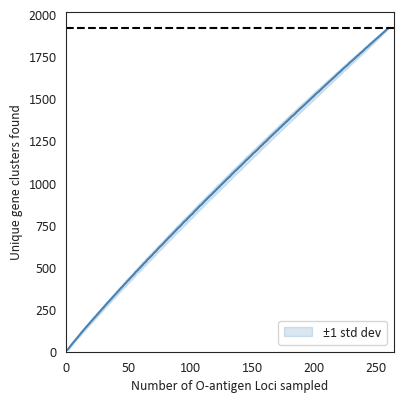

In [3]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import matplotlib as mpl
sns.set_style("white")
# Set Calibri as the primary sans-serif font
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Calibri', 'DejaVu Sans'] # DejaVu Sans serves as a safe fallback
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
model = LinearRegression(fit_intercept=True)
model.fit(np.array(sample_sizes).reshape(-1, 1), curve_means)

plt.figure(figsize=(4.135, 4.135))
slope = model.coef_[0]

r_squared = model.score(np.array(sample_sizes).reshape(-1, 1), curve_means)

print(f"Equation: y = {slope:.2f} * x + {0}")
print(f"R² Coefficient of Determination: {r_squared:.4f}")
# Plot
plt.figure(figsize=(4.135, 4.135))
sns.lineplot(x=sample_sizes, y=curve_means, color='steelblue', linewidth=1.5)
#plt.plot(sample_sizes, slope*np.array(sample_sizes), color='steelblue', linewidth=1.5, linestyle='--', label="Linear regression")
plt.fill_between(
    sample_sizes,
    curve_means - curve_stds,
    curve_means + curve_stds,
    color='steelblue',
    alpha=0.2,
    label='±1 std dev'
)
plt.xlabel("Number of O-antigen Loci sampled")
plt.ylabel("Unique gene clusters found")
#plt.title("Pan-genome sampling curve (gene accumulation)")
plt.xlim(0, n_genomes+4)
plt.ylim(0, pa.shape[1] * 1.05)
plt.axhline(y=max(curve_means), color='k', linestyle='--')

plt.tight_layout()
#plt.text(50,150,f"y = {slope:.2f} * x\nR² = {r_squared:.4f}")
#plt.text(50,100,f"R² = {r_squared:.4f}")
plt.legend()
plt.savefig("sampling_curve.pdf", bbox_inches='tight', format="pdf")
plt.show()

## Most common families

The ten most widespread families are named by inspection and plotted by functional category.

In [4]:
list(matrix.sum().sort_values(ascending=False))

[114,
 93,
 91,
 51,
 37,
 19,
 19,
 18,
 18,
 15,
 14,
 14,
 12,
 12,
 11,
 8,
 8,
 7,
 7,
 7,
 7,
 7,
 6,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 4,
 4,
 4,
 4,
 4,
 4,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,


In [5]:
gene_counts = pd.DataFrame(index=["rmlB", "rmlA", "rmlD","-", "rmlC", "manB", "wbaU", "gmd", "fcl", "manC"], columns=["Counts"], data=list(matrix.sum().sort_values(ascending=False)[0:10])) # assigned on manual insepct

/var/folders/z8/0w6j6rj97tsc58vfqms6447h0000gp/T/ipykernel_80701/3570395161.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(gene_counts,y=gene_counts.index, x=gene_counts.Counts, palette=bar_colors)


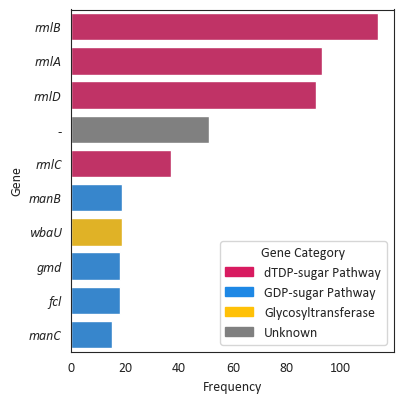

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("white")
plt.figure(figsize=(4.135, 4.135))
# Set Calibri as the primary sans-serif font
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Calibri', 'DejaVu Sans'] # DejaVu Sans serves as a safe fallback

# 2. Assign categories to each data point
categories = ['dTDP-sugar Pathway', 'dTDP-sugar Pathway', 'dTDP-sugar Pathway', 'Unknown', 'dTDP-sugar Pathway', 'GDP-sugar Pathway', 'Glycosyltransferase', 'GDP-sugar Pathway', 'GDP-sugar Pathway', 'GDP-sugar Pathway']

# 3. Define color mapping for categories
category_colors = {
    'dTDP-sugar Pathway': '#D81B60',
    'GDP-sugar Pathway': '#1E88E5',
    'Glycosyltransferase': '#FFC107',
    'Unknown': "grey"
}

bar_colors = [category_colors[cat] for cat in categories]





sns.barplot(gene_counts,y=gene_counts.index, x=gene_counts.Counts, palette=bar_colors)
#plt.xticks(gene_counts.index, fontstyle='italic', rotation=45, ha='right')

handles = [plt.Rectangle((0,0),1,1, color=color) for color in category_colors.values()]
plt.legend(handles, category_colors.keys(), title="Gene Category")

plt.yticks(fontstyle='italic')

plt.xlabel("Frequency")
plt.ylabel("Gene")
plt.tight_layout()
plt.savefig("gene_counts.pdf", bbox_inches='tight', format="pdf")
plt.show()